In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def cylinder_panels(n,r=1):
  theta=np.linspace(2*np.pi,0,n+1)
  x=r*np.cos(theta)
  y=r*np.sin(theta)
  return(x,y)

In [3]:
def naca4_panels(code, n, spacing="cosine"):
    
    m = int(code[0]) / 100        # max camber
    p = int(code[1]) / 10         # location of max camber
    t = int(code[2:]) / 100       # thickness

    half = n // 2
    if spacing == "cosine":
        beta = np.linspace(0, np.pi, half + 1)
        x = 0.5 * (1 - np.cos(beta))
    else:                          # uniform
        x = np.linspace(0, 1, half + 1)

    # thickness distribution (-0.1036 makes the trailing edge closed)
    yt = 5*t*(0.2969*np.sqrt(x) - 0.1260*x - 0.3516*x**2
              + 0.2843*x**3 - 0.1036*x**4)

    # camber line and its slope
    if m == 0:
        yc = np.zeros_like(x)
        dyc = np.zeros_like(x)
    else:
        yc = np.where(x < p,
                      m/p**2 * (2*p*x - x**2),
                      m/(1-p)**2 * ((1 - 2*p) + 2*p*x - x**2))
        dyc = np.where(x < p,
                       2*m/p**2 * (p - x),
                       2*m/(1-p)**2 * (p - x))
    th = np.arctan(dyc)

    xu = x - yt*np.sin(th);  yu = yc + yt*np.cos(th)
    xl = x + yt*np.sin(th);  yl = yc - yt*np.cos(th)

    # clockwise: lower surface from TE to LE, then upper surface LE to TE
    xb = np.concatenate([xl[::-1], xu[1:]])
    yb = np.concatenate([yl[::-1], yu[1:]])
    return xb, yb

In [4]:
def panel_geometry(xb, yb):
    dx = np.diff(xb)
    dy = np.diff(yb)
    xc = 0.5 * (xb[:-1] + xb[1:])      # control points (midpoints)
    yc = 0.5 * (yb[:-1] + yb[1:])
    S = np.hypot(dx, dy)                # panel lengths
    sin_t = dy / S                      # panel angle (relative to x-axis)
    cos_t = dx / S
    return xc, yc, S, sin_t, cos_t

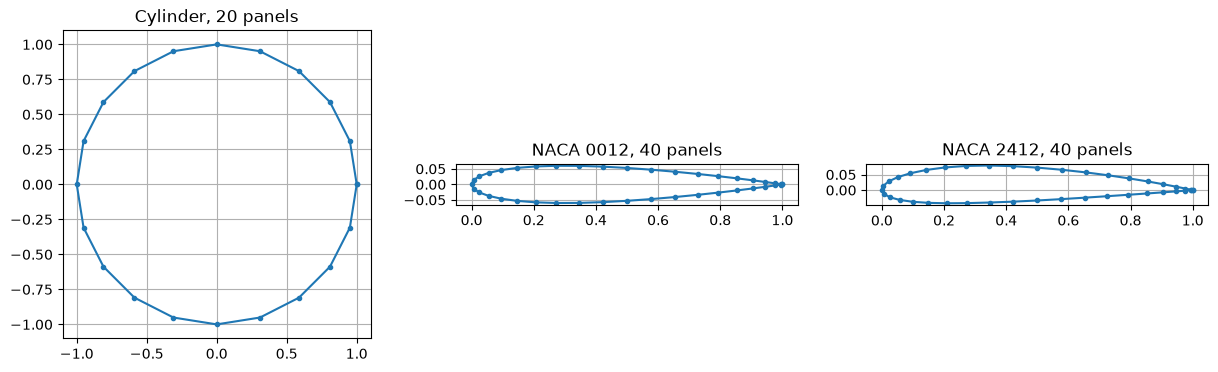

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (name, (xb, yb)) in zip(ax, {
        "Cylinder, 20 panels": cylinder_panels(20),
        "NACA 0012, 40 panels": naca4_panels("0012", 40),
        "NACA 2412, 40 panels": naca4_panels("2412", 40)}.items()):
    a.plot(xb, yb, "o-", ms=3)
    a.set_aspect("equal"); a.set_title(name); a.grid(True)
plt.show()

## Defining Vortex panel method

In [6]:
def vortex_panel_method_0(xb, yb, alpha_deg, V_inf=1.0):
    
    alpha = np.radians(alpha_deg)
    xc, yc, S, sin_t, cos_t = panel_geometry(xb, yb)
    N = len(S)
    theta = np.arctan2(sin_t, cos_t)

                                                # influence-coefficient matrix
    A = np.zeros((N, N))
    for i in range(N):
        for j in range(N):
            if i == j:
                continue                       # self-influence on normal velocity = 0
            dx = xc[i] - xb[j]
            dy = yc[i] - yb[j]
            xi  =  dx*cos_t[j] + dy*sin_t[j]   # local coordinates of point i
            eta = -dx*sin_t[j] + dy*cos_t[j]   # in panel j's frame
            th1 = np.arctan2(eta, xi)
            th2 = np.arctan2(eta, xi - S[j])
            r1 = np.hypot(xi, eta)
            r2 = np.hypot(xi - S[j], eta)
            A[i, j] = ((th2 - th1)*np.sin(theta[j] - theta[i])
                       + np.log(r2/r1)*np.cos(theta[i] - theta[j])) / (2*np.pi)
# first term: along-panel velocity of j, second term: across-panel velocity of j
   
    b = V_inf*np.sin(theta - alpha)

                                              # Kutta condition replaces the last equation
    A[-1, :] = 0.0
    A[-1, 0] = 1.0
    A[-1, -1] = 1.0
    b[-1] = 0.0

   
    gamma = np.linalg.solve(A, b)

    Cp = 1 - (gamma/V_inf)**2
    chord = xb.max() - xb.min()
    Gamma = np.sum(gamma*S)
    Cl = 2*Gamma/(V_inf*chord)
    return {"gamma": gamma, "Cp": Cp, "Cl": Cl, "xc": xc, "yc": yc, "S": S}

### `vortex_panel_method_0`: Constant-Strength Vortex Panels

**Goal:** Find the vortex strength γ on each panel so that no flow passes through the body, then compute Cp and Cl.

- **Inputs:** `xb, yb` (boundary points), `alpha_deg`, `V_inf`
- **Outputs:** `gamma`, `Cp`, `Cl`, `xc`, `yc`, `S`

**Steps:**
1. Get each panel's midpoint, length `S` and angle `theta`.
2. Build matrix `A`: `A[i, j]` is the normal velocity at panel i caused by panel j with unit strength.
3. Set the self-term `A[i, i] = 0`.
4. Build `b` from the free stream: `b = V_inf * sin(theta - alpha)`.
5. Add the Kutta condition `gamma[0] + gamma[N-1] = 0` as an extra equation. It fixes the circulation so the flow leaves the trailing edge smoothly.
6. Solve with `np.linalg.lstsq`. The `rcond` setting removes the zig-zag mode that gives spiky Cp.
7. Compute results:
   - `Cp = 1 - (gamma / V_inf)**2`
   - `Gamma = sum(gamma * S)`
   - `Cl = 2 * Gamma / (V_inf * chord)`

N =   11   max |Cp error| = 1.0871   Cl = -2.49e-15
N =   21   max |Cp error| = 0.5500   Cl = -2.07e-14
N =   41   max |Cp error| = 0.2763   Cl = -2.32e-14
N =   81   max |Cp error| = 0.1384   Cl = 2.67e-14
N =  161   max |Cp error| = 0.0693   Cl = 3.91e-14


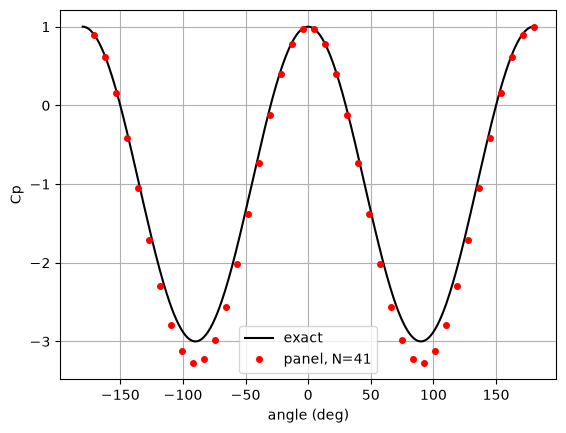

NACA0012, 5 deg, Cl = 0.6047648353301915


In [7]:
# Cylinder: exact solution is Cp = 1 - 4 sin^2(phi), and Cl = 0
# Odd numbers are used to avoid symmetry-related numerical issues and to keep stagnation points away from panel boundaries, resulting in more stable and accurate vortex-panel solutions.
for n in [11, 21, 41, 81, 161]:                                      
    xb, yb = cylinder_panels(n)
    r = vortex_panel_method_0(xb, yb, 0.0)
    phi = np.arctan2(r["yc"], r["xc"])
    err = np.max(np.abs(r["Cp"] - (1 - 4*np.sin(phi)**2)))
    print(f"N = {n:4d}   max |Cp error| = {err:.4f}   Cl = {r['Cl']:.2e}")

# Compare with the exact curve for N = 41
xb, yb = cylinder_panels(41)
r = vortex_panel_method_0(xb, yb, 0.0)
phi = np.arctan2(r["yc"], r["xc"])
pe = np.linspace(-np.pi, np.pi, 400)
plt.plot(np.degrees(pe), 1 - 4*np.sin(pe)**2, "k", label="exact")
plt.plot(np.degrees(phi), r["Cp"], "ro", ms=4, label="panel, N=41")
plt.xlabel("angle (deg)"); plt.ylabel("Cp"); plt.legend(); plt.grid(True)
plt.show()

# Quick airfoil sanity check: NACA 0012 at 5 deg, expect Cl a bit above 0.55
xb, yb = naca4_panels("0012", 160)
print("NACA0012, 5 deg, Cl =", vortex_panel_method_0(xb, yb, 5.0)["Cl"])

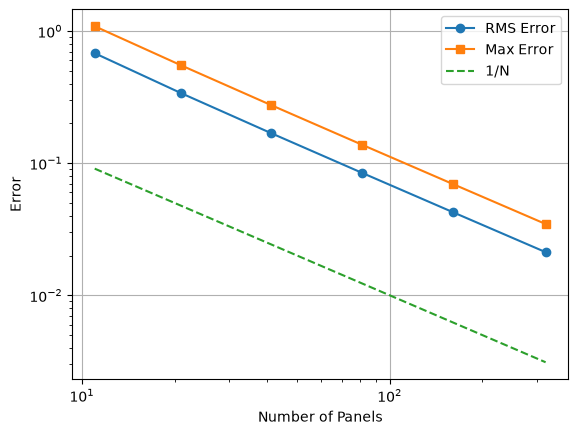

In [8]:
Ns = [11, 21, 41, 81, 161, 321]

max_err = []
rms_err = []

for N in Ns:

    # Create cylinder mesh
    xb, yb = cylinder_panels(N)

    # Solve panel method
    result = vortex_panel_method_0(xb, yb, 0.0)

    # Angle of each control point
    phi = np.arctan2(result["yc"], result["xc"])

    # Exact Cp
    Cp_exact = 1 - 4*np.sin(phi)**2

    # Numerical Cp
    Cp_num = result["Cp"]

    # Error
    error = np.abs(Cp_num - Cp_exact)

    # Store errors
    max_err.append(np.max(error))
    rms_err.append(np.sqrt(np.mean(error**2)))

# Plot error convergence
plt.loglog(Ns, rms_err, 'o-', label="RMS Error")
plt.loglog(Ns, max_err, 's-', label="Max Error")
plt.loglog(Ns, 1/np.array(Ns), '--', label="1/N")                  #order 1

plt.xlabel("Number of Panels")
plt.ylabel("Error")
plt.legend()
plt.grid(True)
plt.show()

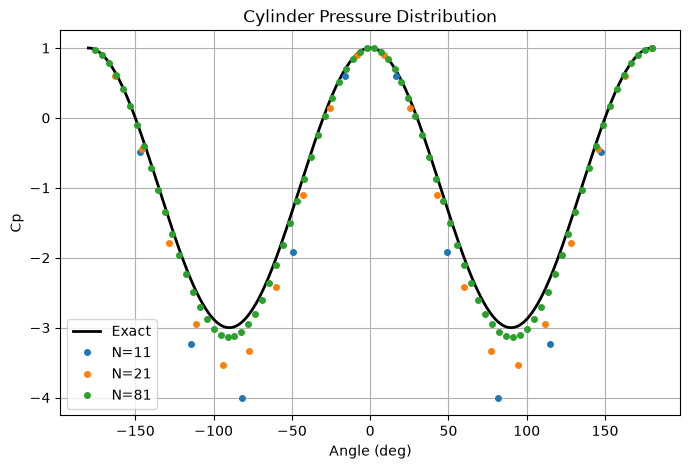

In [9]:
plt.figure(figsize=(8,5))

phi_exact = np.linspace(-np.pi, np.pi, 400)
Cp_exact = 1 - 4*np.sin(phi_exact)**2

plt.plot(np.degrees(phi_exact),
         Cp_exact,
         'k',
         linewidth=2,
         label='Exact')

for N in [11, 21, 81]:
    xb, yb = cylinder_panels(N)
    result = vortex_panel_method_0(xb, yb, 0.0)

    phi = np.arctan2(result["yc"], result["xc"])

    plt.plot(np.degrees(phi),result["Cp"],'o',markersize=4,label=f'N={N}')

plt.xlabel("Angle (deg)")
plt.ylabel("Cp")
plt.title("Cylinder Pressure Distribution")
plt.legend()
plt.grid(True)
plt.show()

### Cylinder Pressure Distribution: Panel Method vs Exact Solution
#### What this graph tells

1. **Exact solution**
   - Make 400 angles from -180° to +180°.
   - For a cylinder in potential flow with no circulation, the exact pressure coefficient is `Cp = 1 - 4 sin²(φ)`.
   - This is plotted as a thick black line.

2. **Panel method solution**
   - Take three panel counts: N = 11, 21 and 81.
   - For each N, create the circle with `cylinder_panels(N)`.
   - Solve the flow with `vortex_panel_method_0` at angle of attack 0° (the angle does not matter for a cylinder).
   - The function returns Cp at the middle point (control point) of every panel.

3. **Finding the angle of each point**
   - `np.arctan2(yc, xc)` gives the angle φ of each control point.
   - This lets us plot the panel results at the same angles as the exact curve.

4. **Plotting**
   - The panel results are drawn as dots, one colour for each N.
   - Labels, title, legend and grid are added to make the plot readable.

**What the plot shows:**

- The dots follow the black curve, so the method works.
- Cp = 1 at the front and back of the cylinder (stagnation points).
- Cp = -3 at the top and bottom (lowest pressure).
- With more panels the dots get closer to the exact curve (N = 81 is almost exact).
- The error is largest at the top and bottom, where the pressure changes fastest.

**Conclusion:** As the number of panels increases, the panel method solution converges to the exact solution.

## Now defining vortex panel method_1-Linear-Strength Vortex Panels

In [10]:
def vortex_panel_method_1(xb, yb, alpha_deg, V_inf=1.0):
    alpha = np.radians(alpha_deg)             #convert to radians
    xc, yc, S, sin_t, cos_t = panel_geometry(xb, yb)
    N = len(S)
    theta = np.arctan2(sin_t, cos_t)

    A = np.zeros((N + 1, N + 1))               #building the matrix
    for i in range(N):
        for j in range(N):
            if i == j:                                   # control point on its own panel,panel acting on itself
                xi, eta, Dth, L = S[j]/2, 0.0, np.pi, 0.0
            else:
                dx = xc[i] - xb[j]
                dy = yc[i] - yb[j]
                xi  =  dx*cos_t[j] + dy*sin_t[j]
                eta = -dx*sin_t[j] + dy*cos_t[j]
                th1 = np.arctan2(eta, xi)
                th2 = np.arctan2(eta, xi - S[j])
                r1 = np.hypot(xi, eta)
                r2 = np.hypot(xi - S[j], eta)
                Dth = th2 - th1                     #angle the panel subtends at the point
                L = np.log(r2/r1)
# J: effect of the constant part of gamma on the panel
# K: effect of the linearly varying part of gamma (extra xi0 factor)
# 1 = velocity along the panel, 2 = velocity across (normal to) the panel
            J1 = Dth
            J2 = -L
            K1 = xi*Dth + eta*L
            K2 = -xi*L - S[j] + eta*Dth

            # local velocity per unit gamma_j (a) and per unit gamma_{j+1} (b)
            uxi_a  =  (J1 - K1/S[j]) / (2*np.pi)
            uxi_b  =  (K1/S[j])      / (2*np.pi)
            ueta_a = -(J2 - K2/S[j]) / (2*np.pi)
            ueta_b = -(K2/S[j])      / (2*np.pi)

            s = np.sin(theta[j] - theta[i])
            c = np.cos(theta[i] - theta[j])
# normal velocity at i due to panel j: gamma[j] part -> column j, gamma[j+1] part -> column j+1
# (+= because shared nodes receive contributions from two panels)
            A[i, j]     += uxi_a*s + ueta_a*c            # the previous term is added
            A[i, j + 1] += uxi_b*s + ueta_b*c

    b = np.zeros(N + 1)
    b[:N] = V_inf*np.sin(theta - alpha)

    # Kutta condition: gamma_1 + gamma_{N+1} = 0
    A[N, 0] = 1.0
    A[N, N] = 1.0
    b[N] = 0.0

    gamma = np.linalg.solve(A, b)

    Vt = 0.5*(gamma[:-1] + gamma[1:])          # surface speed at control points
    Cp = 1 - (Vt/V_inf)**2
    chord = xb.max() - xb.min()
    Gamma = np.sum(S*Vt)
    Cl = 2*Gamma/(V_inf*chord)
    return {"gamma": gamma, "Cp": Cp, "Cl": Cl, "xc": xc, "yc": yc, "S": S}

### `vortex_panel_method_1`: Linear-Strength Vortex Panels

**Goal:** Find the vortex strength at each boundary point, with γ varying linearly along each panel, so that no flow passes through the body. Then compute Cp and Cl.

- **Inputs:** `xb, yb` (boundary points), `alpha_deg`, `V_inf`
- **Outputs:** `gamma` (N+1 nodal values), `Cp`, `Cl`, `xc`, `yc`, `S`

**Steps:**
1. Get each panel's midpoint, length `S` and angle `theta`.
2. There are N+1 unknowns (one γ per boundary point), so `A` is an (N+1) × (N+1) matrix.
3. For each pair of panels, express point i in panel j's own axes and compute `th1`, `th2`, `r1`, `r2`, `Dth` and `L`.
4. Compute `J1`, `J2`, `K1`, `K2`. These are the integrals that account for γ changing along the panel.
5. Each panel j affects two unknowns, `gamma[j]` and `gamma[j+1]`:
   - `A[i, j]` gets the part due to `gamma[j]`.
   - `A[i, j+1]` gets the part due to `gamma[j+1]`.
6. For i = j (a panel acting on its own midpoint), use the special values `xi = S/2`, `eta = 0`, `Dth = π`, `L = 0`.
7. Build `b` from the free stream: `b = V_inf * sin(theta - alpha)`. The last entry is 0.
8. Kutta condition: `gamma[0] + gamma[N] = 0` is the extra (N+1)th equation, so no row has to be replaced.
9. Solve with `np.linalg.solve`.
10. Compute results:
    - Surface speed at each midpoint: `Vt = (gamma[i] + gamma[i+1]) / 2`
    - `Cp = 1 - (Vt / V_inf)**2`
    - `Gamma = sum(S * Vt)`
    - `Cl = 2 * Gamma / (V_inf * chord)`

**Compared with method 0:** the error falls about 4 times when the panels are doubled (second order, against first order for method 0), and it gives smoother Cp on airfoils.

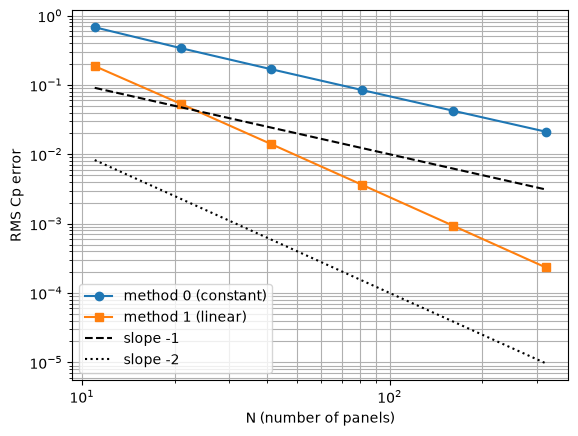

N   11 ->   21:  order m0 = 1.00,  order m1 = 1.82
N   21 ->   41:  order m0 = 1.00,  order m1 = 1.91
N   41 ->   81:  order m0 = 1.00,  order m1 = 1.95
N   81 ->  161:  order m0 = 1.00,  order m1 = 1.98
N  161 ->  321:  order m0 = 1.00,  order m1 = 1.99
0012 Cl method 0 = 0.6048  method 1 = 0.6029
2412 Cl method 0 = 0.8652  method 1 = 0.8615


In [11]:
panel_counts = [11, 21, 41, 81, 161, 321]     # number of panels N (odd values for the cylinder)

#RMS error of Cp on the cylinder
def cylinder_rms_error(method, n_panels):
    xb, yb = cylinder_panels(n_panels)                # boundary points of the circle
    result = method(xb, yb, 0.0)                        # solve at angle of attack 0 deg
    phi = np.arctan2(result["yc"], result["xc"])      # angle of each control point
    cp_exact = 1 - 4*np.sin(phi)**2                      # exact Cp for a cylinder
    cp_error = result["Cp"] - cp_exact                  # error at every panel
    return np.sqrt(np.mean(cp_error**2))                 # root-mean-square of the error

# Error for every N, for both methods 
rms_method0 = []                                     # errors of constant-strength method
rms_method1 = []                                     # errors of linear-strength method
for n in panel_counts:
    rms_method0.append(cylinder_rms_error(vortex_panel_method_0, n))
    rms_method1.append(cylinder_rms_error(vortex_panel_method_1, n))

#Log-log plot
N_array = np.array(panel_counts)                     # convert list to array so we can do maths on it
plt.loglog(panel_counts, rms_method0, "o-", label="method 0 (constant)")
plt.loglog(panel_counts, rms_method1, "s-", label="method 1 (linear)")
plt.loglog(panel_counts, 1.0/N_array,    "k--", label="slope -1")   # reference: error ~ 1/N
plt.loglog(panel_counts, 1.0/N_array**2, "k:",  label="slope -2")   # reference: error ~ 1/N^2
plt.xlabel("N (number of panels)")
plt.ylabel("RMS Cp error")
plt.legend()
plt.grid(True, which="both")
plt.show()

# Observed order of convergence 
# N roughly doubles each step, so order = log2(old error / new error)
for k in range(1, len(panel_counts)):
    order0 = np.log2(rms_method0[k-1] / rms_method0[k])
    order1 = np.log2(rms_method1[k-1] / rms_method1[k])
    print(f"N {panel_counts[k-1]:4d} -> {panel_counts[k]:4d}:  order m0 = {order0:.2f},  order m1 = {order1:.2f}")

# Airfoil check: Cl at 5 deg, N = 160
# N = 160: Cl is converged to about 0.01% (method 1, Stage 6) and the run is still fast
for airfoil_code in ["0012", "2412"]:
    xb, yb = naca4_panels(airfoil_code, 160)         # airfoil boundary points
    cl_method0 = vortex_panel_method_0(xb, yb, 5.0)["Cl"]
    cl_method1 = vortex_panel_method_1(xb, yb, 5.0)["Cl"]
    print(airfoil_code, "Cl method 0 =", round(cl_method0, 4), " method 1 =", round(cl_method1, 4))

**Figure:** RMS error in Cp on a circular cylinder versus number of panels N (log-log). The constant-strength
method (method 0) converges with slope −1 (first order), while the linear-strength method (method 1) approaches
slope −2 (second order). The linear method reaches a given accuracy with far fewer panels.